# Atividade 1: Datação de pinturas com Vision Transformers

**Aluno:** Anderson Corrêa

**Objetivo:** estimar o período em que uma pintura foi feita, entre oito períodos, a partir da imagem. Três modelos são comparados: um Vision Transformer construído à mão e treinado do zero, o mesmo modelo sem embedding posicional e um ViT-B/16 pré-treinado na ImageNet com fine-tuning.

**Requisitos de execução**

- Ambiente: Google Colab com GPU T4
- Memória de GPU: cerca de 4 GB (medido na T4)
- Memória RAM: cerca de 3 GB (processo principal, medido na T4)
- Disco: 5 GB livres
- Tempo estimado: cerca de 16 minutos (medido na T4, sem contar a inicialização da máquina; o download de 1,7 GB pode variar)

**Como executar:** menu *Ambiente de execução*, *Executar tudo*. O notebook baixa os dados sozinho e não precisa de login.

## Código de apoio

As sete células abaixo definem as funções usadas no restante do notebook: execução, dados, laço de treino, atenção, Vision Transformer, dataset de pinturas e gráficos.

- A atenção, o bloco do Transformer e o Vision Transformer estão nas células `attention` e `vit`, escritos com camadas lineares e softmax, sem usar os módulos prontos do PyTorch para atenção.

In [ ]:
"""Run setup and saving shared by the notebooks.

A run seeds the random generators, keeps its figures in one folder and ends
by writing its metrics and packing everything into one archive. The archive
layout is the contract with the script that collects the outputs of a Colab
run: ``metrics.json`` at the top level and the PNG files under ``figures/``.
"""

import json
import random
import sys
from contextlib import contextmanager
from dataclasses import dataclass
from pathlib import Path
from resource import RUSAGE_SELF, getrusage
from time import monotonic
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import torch

BYTES_PER_MEGABYTE = 1e6


class Stopwatch:
    """Measures how long the named steps of a run take.

    ``seconds`` maps every finished step to its duration, in the order the
    steps ran, ready to be saved with the metrics. Each step is also printed
    when it ends, so the cost of a notebook is visible while it runs.
    """

    def __init__(self) -> None:
        """Starts with no step measured."""
        self.seconds = {}

    @contextmanager
    def measure(self, name: str):
        """Times the body of a ``with`` block and records it under ``name``.

        A block that raises is not recorded.
        """
        started_at = monotonic()
        yield
        self.seconds[name] = round(monotonic() - started_at, 1)
        print(f"{name}: {self.seconds[name]} s")


@dataclass(frozen=True)
class Run:
    """One notebook run: its activity, its output folders and when it started.

    ``started_at`` is a reading of the monotonic clock, good only for
    measuring elapsed time.
    """

    activity: str
    output_dir: Path
    figures_dir: Path
    started_at: float


def seed_everything(seed: int) -> None:
    """Seeds the random generators of Python, numpy and torch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def start_run(activity: str) -> Run:
    """Prepares the output folders of an activity and starts its timer.

    Creates ``outputs/<activity>/figures`` under the current directory. The
    peak GPU memory counter is reset when CUDA is available, so the peak saved
    later belongs to this run only.
    """
    output_dir = Path("outputs") / activity
    figures_dir = output_dir / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    return Run(activity, output_dir, figures_dir, monotonic())


def peak_gpu_memory_mb() -> float:
    """Returns the peak memory allocated by PyTorch on the GPU, or 0.0 without CUDA."""
    if not torch.cuda.is_available():
        return 0.0
    return torch.cuda.max_memory_allocated() / BYTES_PER_MEGABYTE


def peak_ram_mb() -> float:
    """Returns the peak resident memory of the main process, in megabytes.

    Data loader worker processes are not included. The operating system
    reports the value in kilobytes on Linux and in bytes on macOS.
    """
    peak = getrusage(RUSAGE_SELF).ru_maxrss
    peak_bytes = peak if sys.platform == "darwin" else peak * 1024
    return peak_bytes / BYTES_PER_MEGABYTE


def save_run(run: Run, metrics: dict) -> Path:
    """Writes the metrics of a run and packs them with its figures.

    A copy of ``metrics`` gains ``runtime_seconds``, ``peak_gpu_memory_mb``
    and ``peak_ram_mb`` and is written to ``outputs/<activity>/metrics.json``.
    The archive ``outputs_<activity>.zip`` is created in the current directory
    and its path is returned.
    """
    saved = {
        **metrics,
        "runtime_seconds": round(monotonic() - run.started_at, 1),
        "peak_gpu_memory_mb": round(peak_gpu_memory_mb(), 1),
        "peak_ram_mb": round(peak_ram_mb(), 1),
    }
    metrics_path = run.output_dir / "metrics.json"
    metrics_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False), encoding="utf-8")
    archive = Path(f"outputs_{run.activity}.zip")
    with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
        bundle.write(metrics_path, "metrics.json")
        for figure in sorted(run.figures_dir.glob("*.png")):
            bundle.write(figure, f"figures/{figure.name}")
    return archive


In [ ]:
"""Dataset download, image discovery, splitting and preprocessing shared by the notebooks."""

from collections import Counter
from hashlib import sha256
from pathlib import Path
from zipfile import ZipFile

import torch
from PIL import Image
from requests import get
from sklearn.model_selection import train_test_split
from torch import Tensor
from torch.nn.functional import pad
from torch.utils.data import Dataset
from torchvision.transforms import CenterCrop, Compose, Normalize, Resize, ToTensor

KAGGLE_DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/{slug}"
IMAGE_SUFFIXES = {".bmp", ".jpg", ".jpeg", ".png"}
MINIMUM_IMAGES_PER_CLASS = 7
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def download_kaggle_dataset(slug: str, destination: Path) -> Path:
    """Downloads and extracts a public Kaggle dataset, once.

    A marker file records a finished download, so calling this again for the
    same destination returns immediately. No Kaggle account is needed.
    """
    destination = Path(destination)
    marker = destination / ".complete"
    if marker.exists():
        return destination
    destination.mkdir(parents=True, exist_ok=True)
    archive = destination / "archive.zip"
    with get(KAGGLE_DOWNLOAD_URL.format(slug=slug), stream=True, timeout=60) as response:
        response.raise_for_status()
        with open(archive, "wb") as handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                handle.write(chunk)
    with ZipFile(archive) as bundle:
        bundle.extractall(destination)
    archive.unlink()
    marker.touch()
    return destination


def has_image_name(path: Path) -> bool:
    """Tells whether a path is named like a visible image file."""
    return not path.name.startswith(".") and path.suffix.lower() in IMAGE_SUFFIXES


def count_image_files(root: Path) -> int:
    """Counts the visible files under root that are named like images.

    Nothing is opened, so exact copies and files that cannot be decoded are
    counted too. This is the size of a download before any cleaning.
    """
    return sum(1 for path in Path(root).rglob("*") if path.is_file() and has_image_name(path))


def is_readable_image(path: Path) -> bool:
    """Tells whether a file is a visible image that Pillow can decode."""
    if not has_image_name(path):
        return False
    try:
        with Image.open(path) as image:
            image.load()
    except (OSError, SyntaxError, ValueError):
        return False
    return True


def file_digest(path: Path) -> str:
    """Returns the SHA-256 hash of a file's bytes."""
    return sha256(path.read_bytes()).hexdigest()


def list_image_folder(root: Path) -> tuple[list[Path], list[int], list[str]]:
    """Finds every readable image under root and labels it by its parent folder.

    Returns the image paths, one integer label per path, and the class names
    in the order used by the labels. Unreadable files are left out. Exact
    copies within one class keep only the first path in sorted order. Files
    with identical content under two or more classes have an ambiguous label,
    so all of them are left out.
    """
    groups = {}
    for path in sorted(path for path in Path(root).rglob("*") if path.is_file() and is_readable_image(path)):
        groups.setdefault(file_digest(path), []).append(path)
    paths = sorted(
        group[0] for group in groups.values() if len({path.parent.name for path in group}) == 1
    )
    class_names = sorted({path.parent.name for path in paths})
    index = {name: position for position, name in enumerate(class_names)}
    labels = [index[path.parent.name] for path in paths]
    return paths, labels, class_names


def stratified_split(
    labels: list[int],
    fractions: tuple[float, float, float] = (0.7, 0.15, 0.15),
    seed: int = 42,
) -> tuple[list[int], list[int], list[int]]:
    """Splits indices into train, validation and test, keeping class shares.

    Raises ValueError naming the class when a class is too small to appear in
    all three parts.
    """
    for label, count in sorted(Counter(labels).items()):
        if count < MINIMUM_IMAGES_PER_CLASS:
            raise ValueError(
                f"class {label} has {count} images; at least {MINIMUM_IMAGES_PER_CLASS} are needed to split"
            )
    indices = list(range(len(labels)))
    train, rest = train_test_split(
        indices, train_size=fractions[0], stratify=labels, random_state=seed
    )
    validation_share = fractions[1] / (fractions[1] + fractions[2])
    validation, test = train_test_split(
        rest,
        train_size=validation_share,
        stratify=[labels[i] for i in rest],
        random_state=seed,
    )
    return sorted(train), sorted(validation), sorted(test)


class ImageListDataset(Dataset):
    """Serves transformed images and labels from parallel lists."""

    def __init__(self, paths: list[Path], labels: list[int], transform):
        """Stores the image paths, their labels and the transform to apply."""
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self) -> int:
        """Returns the number of images."""
        return len(self.paths)

    def __getitem__(self, index: int):
        """Loads one image as RGB and returns it transformed, with its label."""
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert("RGB")), self.labels[index]


def imagenet_transform(resize_size: int = 232, crop_size: int = 224) -> Compose:
    """Returns the evaluation preprocessing of a backbone pre-trained on ImageNet.

    The short side is resized to ``resize_size``, a centre square of
    ``crop_size`` is cut out and the channels are normalized with the ImageNet
    mean and standard deviation. The defaults are the published preset of the
    ResNet-50 ``IMAGENET1K_V2`` weights. Other weights may use other sizes.
    """
    return Compose(
        [
            Resize(resize_size),
            CenterCrop(crop_size),
            ToTensor(),
            Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]
    )


def random_crop_flip(images: Tensor, padding: int, generator: torch.Generator) -> Tensor:
    """Shifts and mirrors every image of a batch at random, keeping its size.

    Each image shaped (channels, size, size) is padded with zeros on every
    side, a window of the original size is cut at a random offset, and the
    window is mirrored left to right with probability one half. Every image
    gets its own offset and its own coin. The random numbers are drawn on the
    CPU from ``generator``, so a seed fixes the result on any device.
    """
    count, channels, height, width = images.shape
    device = images.device
    top = torch.randint(0, 2 * padding + 1, (count,), generator=generator).to(device)
    left = torch.randint(0, 2 * padding + 1, (count,), generator=generator).to(device)
    mirrored = (torch.rand(count, generator=generator) < 0.5).to(device)
    rows = top[:, None] + torch.arange(height, device=device)
    forward = left[:, None] + torch.arange(width, device=device)
    backward = left[:, None] + torch.arange(width - 1, -1, -1, device=device)
    columns = torch.where(mirrored[:, None], backward, forward)
    padded = pad(images, (padding, padding, padding, padding))
    return padded[
        torch.arange(count, device=device)[:, None, None, None],
        torch.arange(channels, device=device)[None, :, None, None],
        rows[:, None, :, None],
        columns[:, None, None, :],
    ]


def channel_statistics(images: Tensor) -> tuple[tuple[float, ...], tuple[float, ...]]:
    """Returns the mean and standard deviation of each channel of uint8 images.

    Pixels are scaled to the range 0 to 1 first, which is the scale
    ``TensorBatches`` normalizes on.
    """
    scaled = images.float() / 255
    mean = scaled.mean(dim=(0, 2, 3))
    std = scaled.std(dim=(0, 2, 3), correction=0)
    return tuple(mean.tolist()), tuple(std.tolist())


class TensorBatches:
    """Batches of normalized images served from uint8 tensors held in memory.

    Stands in for a data loader when a whole split fits in memory: iterating
    yields ``(images, labels)`` batches of float images, and every new
    iteration is one epoch. The tensors live on ``device``, so with a GPU no
    data moves between devices during training. Shuffling and augmentation
    (random shift of up to ``padding`` pixels and mirroring) are fixed by
    ``seed`` and change from one epoch to the next.
    """

    def __init__(
        self,
        images: Tensor,
        labels: Tensor,
        batch_size: int,
        mean: tuple[float, ...],
        std: tuple[float, ...],
        augment: bool = False,
        shuffle: bool = False,
        padding: int = 4,
        seed: int = 0,
        device: torch.device | str = "cpu",
    ):
        """Moves the images and labels to the device and stores the batch settings."""
        self.images = images.to(device)
        self.labels = torch.as_tensor(labels, dtype=torch.long).to(device)
        self.batch_size = batch_size
        self.mean = torch.tensor(mean, device=device).view(1, -1, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, -1, 1, 1)
        self.augment = augment
        self.shuffle = shuffle
        self.padding = padding
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self) -> int:
        """Returns the number of batches in one epoch."""
        return -(-self.images.shape[0] // self.batch_size)

    def __iter__(self):
        """Yields the batches of one epoch."""
        count = self.images.shape[0]
        if self.shuffle:
            order = torch.randperm(count, generator=self.generator).to(self.images.device)
        else:
            order = torch.arange(count, device=self.images.device)
        for start in range(0, count, self.batch_size):
            chosen = order[start : start + self.batch_size]
            images = self.images[chosen]
            if self.augment:
                images = random_crop_flip(images, self.padding, self.generator)
            yield (images.float() / 255 - self.mean) / self.std, self.labels[chosen]


In [ ]:
"""Training loop and evaluation for image classifiers."""

from math import cos, pi

import torch
from torch import nn
from torch.amp import GradScaler, autocast
from torch.nn.functional import cross_entropy
from torch.optim.lr_scheduler import LambdaLR


def train_all(model: nn.Module) -> None:
    """Puts every layer of the model in training mode."""
    model.train()


def run_epoch(
    model, loader, device, optimizer=None, scheduler=None, use_amp: bool = False, scaler=None
) -> tuple[float, float]:
    """Runs one pass over a loader and returns mean loss and accuracy.

    The model is updated only when an optimizer is given. An empty loader
    yields zeros. The scheduler, when given, is stepped once per training
    batch. ``use_amp`` turns on mixed precision with gradient scaling on CUDA
    and does nothing on other devices. Pass a ``scaler`` to keep one gradient
    scale across epochs; without it a new one is made for this pass.
    """
    training = optimizer is not None
    amp_enabled = use_amp and device.type == "cuda"
    if scaler is None:
        scaler = GradScaler(device.type, enabled=amp_enabled)
    total_loss = 0.0
    correct = 0
    count = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            with autocast(device.type, enabled=amp_enabled):
                logits = model(images)
                loss = cross_entropy(logits, labels)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / max(count, 1), correct / max(count, 1)


def fit(
    model,
    train_loader,
    validation_loader,
    optimizer,
    epochs: int,
    device,
    set_train_mode=train_all,
    scheduler=None,
    use_amp: bool = False,
) -> dict[str, list[float]]:
    """Trains a classifier and returns loss and accuracy for every epoch.

    ``set_train_mode`` decides which layers train. Pass a custom function to
    keep a frozen backbone in evaluation mode. ``scheduler`` and ``use_amp``
    are passed to every training pass.
    """
    scaler = GradScaler(device.type, enabled=use_amp and device.type == "cuda")
    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(epochs):
        set_train_mode(model)
        train_loss, train_accuracy = run_epoch(model, train_loader, device, optimizer, scheduler, use_amp, scaler)
        model.eval()
        val_loss, val_accuracy = run_epoch(model, validation_loader, device, use_amp=use_amp)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        print(
            f"epoch {epoch + 1}/{epochs} "
            f"train loss {train_loss:.4f} acc {train_accuracy:.4f} "
            f"val loss {val_loss:.4f} acc {val_accuracy:.4f}"
        )
    return history


def evaluate(model, loader, device, num_classes: int, use_amp: bool = False) -> dict:
    """Measures overall accuracy, accuracy per class and the confusion matrix.

    Confusion rows are true classes and columns are predicted classes. The
    predicted and true classes of every sample are also returned as lists of
    ints in loader order. ``use_amp`` runs the forward pass in mixed precision
    on CUDA and does nothing on other devices.
    """
    model.eval()
    all_predictions = []
    all_targets = []
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)
    with torch.no_grad():
        for images, labels in loader:
            with autocast(device.type, enabled=use_amp and device.type == "cuda"):
                logits = model(images.to(device))
            predictions = logits.argmax(dim=1).cpu()
            for truth, prediction in zip(labels.tolist(), predictions.tolist()):
                confusion[truth, prediction] += 1
                all_targets.append(truth)
                all_predictions.append(prediction)
    hits = confusion.diag()
    per_class = (hits / confusion.sum(dim=1).clamp(min=1)).tolist()
    accuracy = (hits.sum() / confusion.sum().clamp(min=1)).item()
    return {
        "accuracy": accuracy,
        "per_class_accuracy": per_class,
        "confusion": confusion.tolist(),
        "predictions": all_predictions,
        "targets": all_targets,
    }


def macro_f1(confusion: list[list[int]]) -> float:
    """Averages the F1 score of every class of a confusion matrix.

    Rows are true classes and columns are predicted classes. A class with no
    samples and no predictions scores zero.
    """
    size = len(confusion)
    scores = []
    for index in range(size):
        hits = confusion[index][index]
        predicted = sum(row[index] for row in confusion)
        actual = sum(confusion[index])
        denominator = predicted + actual
        scores.append(2 * hits / denominator if denominator else 0.0)
    return sum(scores) / max(size, 1)


def mean_class_distance(confusion: list[list[int]]) -> float:
    """Averages |true index - predicted index| over all samples.

    Useful when classes are ordered, such as periods in time. An empty matrix
    gives zero.
    """
    total = sum(sum(row) for row in confusion)
    distance = sum(
        count * abs(truth - prediction)
        for truth, row in enumerate(confusion)
        for prediction, count in enumerate(row)
    )
    return distance / max(total, 1)


def within_distance_accuracy(confusion: list[list[int]], distance: int = 1) -> float:
    """Returns the share of samples predicted at most ``distance`` classes from the truth.

    Rows are true classes and columns are predicted classes, in an order that
    has meaning, such as periods in time. An empty matrix gives zero.
    """
    total = sum(sum(row) for row in confusion)
    near = sum(
        count
        for truth, row in enumerate(confusion)
        for prediction, count in enumerate(row)
        if abs(truth - prediction) <= distance
    )
    return near / max(total, 1)


def warmup_cosine_schedule(optimizer, warmup_steps: int, total_steps: int) -> LambdaLR:
    """Schedules a linear warm-up followed by a cosine decay, counted in steps.

    The rate of every parameter group rises in equal steps to its base value
    over ``warmup_steps``, then falls along half a cosine and reaches zero at
    ``total_steps``. Steps past the total keep the rate at zero. The scheduler
    is meant to be stepped once per training batch, as ``fit`` does.
    """
    decay_steps = max(total_steps - warmup_steps, 1)

    def factor(step: int) -> float:
        """Returns the multiplier of the base rate at one step."""
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = min((step - warmup_steps) / decay_steps, 1.0)
        return 0.5 * (1 + cos(pi * progress))

    return LambdaLR(optimizer, factor)


In [ ]:
"""Attention mechanism and Transformer encoder block built from linear layers and softmax."""

from math import sqrt

import torch
from torch import Tensor, nn


def scaled_dot_product_attention(
    query: Tensor, key: Tensor, value: Tensor, mask: Tensor | None = None
) -> tuple[Tensor, Tensor]:
    """Computes softmax(Q K^T / sqrt(d)) V and returns the output with the weights.

    Args:
        query: tensor shaped (..., queries, d).
        key: tensor shaped (..., keys, d).
        value: tensor shaped (..., keys, d_value).
        mask: optional boolean tensor broadcastable to (..., queries, keys),
            true where attention is allowed.

    A query with no allowed key gets all-zero weights and a zero output
    instead of NaN, and its gradients stay finite.
    """
    scores = query @ key.transpose(-2, -1) / sqrt(query.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
    weights = torch.softmax(scores, dim=-1)
    if mask is not None:
        weights = weights * mask
    return weights @ value, weights


class MultiHeadAttention(nn.Module):
    """Multi-head self-attention where every head owns its query, key and value layers.

    Each head projects the input from embed_dim to embed_dim // num_heads with
    separate linear layers. Head outputs are concatenated and mixed by one
    output projection.
    """

    def __init__(self, embed_dim: int, num_heads: int, dropout: float = 0.0):
        """Creates the per-head projections and the output projection."""
        super().__init__()
        if embed_dim % num_heads != 0:
            raise ValueError(
                f"embed_dim {embed_dim} must be divisible by num_heads {num_heads}"
            )
        head_dim = embed_dim // num_heads
        self.num_heads = num_heads
        self.query = nn.ModuleList(nn.Linear(embed_dim, head_dim) for _ in range(num_heads))
        self.key = nn.ModuleList(nn.Linear(embed_dim, head_dim) for _ in range(num_heads))
        self.value = nn.ModuleList(nn.Linear(embed_dim, head_dim) for _ in range(num_heads))
        self.output_projection = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: Tensor, return_weights: bool = False) -> Tensor | tuple[Tensor, Tensor]:
        """Attends over the tokens of x shaped (batch, tokens, embed_dim).

        Returns the output, or (output, weights) with weights shaped
        (batch, heads, tokens, tokens) when return_weights is true.
        """
        outputs, all_weights = [], []
        for query, key, value in zip(self.query, self.key, self.value):
            output, weights = scaled_dot_product_attention(query(x), key(x), value(x))
            outputs.append(output)
            all_weights.append(weights)
        merged = self.output_projection(torch.cat(outputs, dim=-1))
        merged = self.dropout(merged)
        if return_weights:
            return merged, torch.stack(all_weights, dim=1)
        return merged


class TransformerEncoderBlock(nn.Module):
    """Pre-norm Transformer encoder block: attention and feedforward, each with a residual."""

    def __init__(self, embed_dim: int, num_heads: int, mlp_dim: int, dropout: float = 0.0):
        """Creates the two layer norms, the attention and the two-layer feedforward."""
        super().__init__()
        self.attention_norm = nn.LayerNorm(embed_dim)
        self.attention = MultiHeadAttention(embed_dim, num_heads, dropout)
        self.feedforward_norm = nn.LayerNorm(embed_dim)
        self.feedforward = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x: Tensor, return_weights: bool = False) -> Tensor | tuple[Tensor, Tensor]:
        """Applies the block to x shaped (batch, tokens, embed_dim).

        Returns the output, or (output, weights) when return_weights is true.
        """
        attended, weights = self.attention(self.attention_norm(x), return_weights=True)
        x = x + attended
        x = x + self.feedforward(self.feedforward_norm(x))
        if return_weights:
            return x, weights
        return x


In [ ]:
"""Vision Transformer built from patch embedding and encoder blocks, and a pre-trained one to fine-tune."""

import torch
from torch import Tensor, nn
from torchvision.models import ViT_B_16_Weights, vit_b_16



class PatchEmbedding(nn.Module):
    """Cuts an image into non-overlapping square patches and embeds each as a token."""

    def __init__(self, image_size: int, patch_size: int, in_channels: int, embed_dim: int):
        """Creates the strided convolution that projects every patch linearly."""
        super().__init__()
        if image_size % patch_size != 0:
            raise ValueError(
                f"image_size {image_size} must be divisible by patch_size {patch_size}"
            )
        self.image_size = image_size
        self.grid_size = image_size // patch_size
        self.num_patches = self.grid_size**2
        self.projection = nn.Conv2d(
            in_channels, embed_dim, kernel_size=patch_size, stride=patch_size
        )

    def forward(self, images: Tensor) -> Tensor:
        """Maps (batch, channels, size, size) to (batch, patches, embed_dim)."""
        if images.shape[-2:] != (self.image_size, self.image_size):
            raise ValueError(
                f"expected images of size {self.image_size}x{self.image_size}, "
                f"got {images.shape[-2]}x{images.shape[-1]}"
            )
        return self.projection(images).flatten(2).transpose(1, 2)


class VisionTransformer(nn.Module):
    """Vision Transformer classifier reading the class token after a stack of encoder blocks.

    Self-attention treats its input tokens as a set, so the order of the
    patches reaches the model only through the positional embedding.
    """

    def __init__(
        self,
        image_size: int = 64,
        patch_size: int = 8,
        num_classes: int = 8,
        embed_dim: int = 192,
        depth: int = 6,
        num_heads: int = 3,
        mlp_dim: int = 768,
        dropout: float = 0.1,
        use_positional_embedding: bool = True,
    ):
        """Creates the patch embedding, class token, optional positions, blocks and head."""
        super().__init__()
        self.patch_embedding = PatchEmbedding(image_size, patch_size, 3, embed_dim)
        tokens = self.patch_embedding.num_patches + 1
        self.class_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        nn.init.trunc_normal_(self.class_token, std=0.02)
        if use_positional_embedding:
            self.positional_embedding = nn.Parameter(torch.zeros(1, tokens, embed_dim))
            nn.init.trunc_normal_(self.positional_embedding, std=0.02)
        else:
            self.register_parameter("positional_embedding", None)
        self.dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(
            TransformerEncoderBlock(embed_dim, num_heads, mlp_dim, dropout)
            for _ in range(depth)
        )
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

    def forward(
        self, images: Tensor, return_attention: bool = False
    ) -> Tensor | tuple[Tensor, list[Tensor]]:
        """Classifies images shaped (batch, 3, size, size).

        Returns logits, or (logits, attention) where attention lists one
        (batch, heads, tokens, tokens) tensor per block.
        """
        tokens = self.patch_embedding(images)
        class_token = self.class_token.expand(tokens.shape[0], -1, -1)
        tokens = torch.cat([class_token, tokens], dim=1)
        if self.positional_embedding is not None:
            tokens = tokens + self.positional_embedding
        tokens = self.dropout(tokens)
        attention = []
        for block in self.blocks:
            tokens, weights = block(tokens, return_weights=True)
            attention.append(weights)
        logits = self.head(self.norm(tokens)[:, 0])
        if return_attention:
            return logits, attention
        return logits


def class_token_attention(attention: Tensor, grid_size: int) -> Tensor:
    """Extracts the class token's attention to every patch as a spatial map.

    Args:
        attention: one block's weights shaped (batch, heads, tokens, tokens),
            with the class token at index 0.
        grid_size: patches per image side.

    Returns a tensor shaped (batch, heads, grid_size, grid_size).
    """
    patches = attention[:, :, 0, 1:]
    return patches.reshape(*patches.shape[:2], grid_size, grid_size)


def build_pretrained_vit(
    num_classes: int, weights: ViT_B_16_Weights | None = ViT_B_16_Weights.IMAGENET1K_V1
) -> nn.Module:
    """Builds a torchvision ViT-B/16 with a new head, ready for full fine-tuning.

    The classification head is replaced by a fresh linear layer with one
    output per class. Every layer keeps receiving gradients. Pass
    ``weights=None`` to skip the download and start from random weights.
    """
    model = vit_b_16(weights=weights)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model


def fine_tuning_groups(model: nn.Module, backbone_lr: float, head_lr: float) -> list[dict]:
    """Splits the parameters of a torchvision ViT into backbone and head groups.

    Returns two optimizer parameter groups, backbone first, each with its own
    learning rate. The new head starts from random weights and can take a much
    larger rate than the pre-trained layers.
    """
    head = list(model.heads.parameters())
    head_ids = {id(parameter) for parameter in head}
    backbone = [parameter for parameter in model.parameters() if id(parameter) not in head_ids]
    return [{"params": backbone, "lr": backbone_lr}, {"params": head, "lr": head_lr}]


In [ ]:
"""Paintings dataset: year parsing, balanced sampling, painter-wise splitting and image reading."""

import re
from collections import defaultdict
from io import BytesIO
from pathlib import Path
from random import Random
from unicodedata import combining, normalize

import numpy as np
import torch
from PIL import Image
from pyarrow.compute import struct_field
from pyarrow.parquet import ParquetFile, read_table
from requests import get
from torch import Tensor
from torch.utils.data import Dataset

WIKIART_API_URL = "https://huggingface.co/api/datasets/Artificio/WikiArt"
WIKIART_FILE_URL = "https://huggingface.co/datasets/Artificio/WikiArt/resolve/main/{path}"
PERIODS = [
    ("até 1599", 0, 1599),
    ("1600 a 1799", 1600, 1799),
    ("1800 a 1849", 1800, 1849),
    ("1850 a 1874", 1850, 1874),
    ("1875 a 1899", 1875, 1899),
    ("1900 a 1924", 1900, 1924),
    ("1925 a 1949", 1925, 1949),
    ("1950 em diante", 1950, 9999),
]
YEAR_PATTERN = re.compile(r"(?<!\d)(1\d{3}|20[0-2]\d)(?!\d)")
UNKNOWN_ARTIST_NAMES = {"", "none", "nan", "null", "anonymous", "anonymous artist"}


def parse_year(text) -> int | None:
    """Returns the first four-digit year from 1000 to 2029 found in a text.

    Forms such as ``1920``, ``1997.0`` and ``c.1904`` all yield their year.
    Anything without such a year, including ``None``, yields ``None``.
    """
    match = YEAR_PATTERN.search(str(text)) if text is not None else None
    return int(match.group()) if match else None


def period_of(year: int) -> int:
    """Returns the index into ``PERIODS`` of the period holding a year."""
    for index, (_, first, last) in enumerate(PERIODS):
        if first <= year <= last:
            return index
    raise ValueError(f"year {year} is outside every period")


def download_wikiart(destination: Path) -> list[Path]:
    """Downloads the WikiArt parquet files from Hugging Face, once each.

    The file list comes from the Hugging Face API. Each file is streamed to a
    temporary name and renamed when complete, so an interrupted run never
    leaves a partial parquet file. A ``.complete`` marker written last makes a
    repeated call return immediately. Returns the local paths, sorted.
    """
    destination = Path(destination)
    marker = destination / ".complete"
    if marker.exists():
        return sorted(destination.glob("*.parquet"))
    destination.mkdir(parents=True, exist_ok=True)
    with get(WIKIART_API_URL, timeout=60) as response:
        response.raise_for_status()
        listing = response.json()
    remote_paths = sorted(
        entry["rfilename"]
        for entry in listing["siblings"]
        if entry["rfilename"].startswith("data/") and entry["rfilename"].endswith(".parquet")
    )
    local_paths = []
    for remote_path in remote_paths:
        target = destination / Path(remote_path).name
        local_paths.append(target)
        if target.exists():
            continue
        partial = target.with_suffix(".part")
        with get(WIKIART_FILE_URL.format(path=remote_path), stream=True, timeout=60) as response:
            response.raise_for_status()
            with open(partial, "wb") as handle:
                for chunk in response.iter_content(chunk_size=1 << 20):
                    handle.write(chunk)
        partial.rename(target)
    marker.touch()
    return sorted(local_paths)


def read_metadata(parquet_paths) -> dict[str, list]:
    """Reads the year, artist, style and title of every painting, without the images.

    Only the ``date``, ``artist``, ``style`` and ``title`` columns are read.
    The result holds parallel lists under ``year`` (int or None), ``artist``,
    ``style``, ``title`` and ``row``, the global row number counted across the
    files in path order.
    """
    metadata = {"year": [], "artist": [], "style": [], "title": [], "row": []}
    offset = 0
    for path in parquet_paths:
        table = read_table(path, columns=["date", "artist", "style", "title"])
        metadata["year"].extend(parse_year(value) for value in table.column("date").to_pylist())
        metadata["artist"].extend(table.column("artist").to_pylist())
        metadata["style"].extend(table.column("style").to_pylist())
        metadata["title"].extend(table.column("title").to_pylist())
        metadata["row"].extend(range(offset, offset + table.num_rows))
        offset += table.num_rows
    return metadata


def row_group_sizes(parquet_paths) -> list[list[int]]:
    """Returns the number of rows of every row group, one list per file.

    ``read_images`` loads one row group at a time, so the largest group sets
    how much memory a read needs. Only the file footers are read.
    """
    sizes = []
    for path in parquet_paths:
        details = ParquetFile(path).metadata
        sizes.append([details.row_group(index).num_rows for index in range(details.num_row_groups)])
    return sizes


def select_balanced(labels: list[int | None], per_class: int, seed: int) -> list[int]:
    """Picks up to ``per_class`` indices of each class, leaving out ``None`` labels.

    The pick is random but fixed by the seed. Classes with fewer rows keep all
    of them. Returns the chosen indices sorted.
    """
    members = defaultdict(list)
    for index, label in enumerate(labels):
        if label is not None:
            members[label].append(index)
    chosen = []
    for label in sorted(members):
        indices = members[label]
        if len(indices) > per_class:
            indices = Random(f"{seed}:{label}").sample(indices, per_class)
        chosen.extend(indices)
    return sorted(chosen)


def is_unknown_artist(name) -> bool:
    """Tells whether an artist value is empty or some spelling of "unknown"."""
    text = str(name).strip().lower() if name is not None else ""
    return text in UNKNOWN_ARTIST_NAMES or text.startswith("unknown")


def spelling_variants(names) -> list[list[str]]:
    """Finds names written in more than one way.

    Two spellings are taken as the same name when they match after ignoring
    case, accents, punctuation, spacing and word order, so ``Monet, Claude``
    and ``claude-monet`` fall together. Returns one sorted list of spellings
    for every name that has at least two, ordered by first spelling. Empty
    names and ``None`` are skipped. Nothing is merged or corrected here.
    """
    spellings = defaultdict(set)
    for name in names:
        text = str(name).strip() if name is not None else ""
        plain = "".join(letter for letter in normalize("NFKD", text) if not combining(letter))
        key = " ".join(sorted(re.sub(r"[^0-9a-z]+", " ", plain.casefold()).split()))
        if key:
            spellings[key].add(text)
    return sorted(sorted(group) for group in spellings.values() if len(group) > 1)


def split_by_group(
    groups: list[str],
    labels: list[int],
    fractions: tuple[float, float, float] = (0.7, 0.15, 0.15),
    seed: int = 42,
) -> tuple[list[int], list[int], list[int]]:
    """Splits indices into train, validation and test with no group in two parts.

    Whole groups are assigned, largest first, to the part whose class-wise
    quota they fill best, so part sizes follow the fractions and every class
    reaches every part when the data allows. A group that is empty or an
    unknown artist stands for no real painter, so each such row is its own
    group. The result is fixed by the seed. Returns three sorted index lists.
    """
    members = defaultdict(list)
    for index, group in enumerate(groups):
        key = ("row", index) if is_unknown_artist(group) else ("artist", group)
        members[key].append(index)
    classes = sorted(set(labels))
    class_position = {label: position for position, label in enumerate(classes)}
    totals = np.zeros(len(classes))
    for label in labels:
        totals[class_position[label]] += 1
    shares = np.array(fractions) / sum(fractions)
    quota = np.maximum(shares[:, None] * totals[None, :], 1e-9)
    filled = np.zeros_like(quota)
    order = sorted(members, key=repr)
    Random(seed).shuffle(order)
    order.sort(key=lambda key: -len(members[key]))
    parts = ([], [], [])
    for key in order:
        counts = np.zeros(len(classes))
        for index in members[key]:
            counts[class_position[labels[index]]] += 1
        room = (quota - filled) / quota
        scores = (room * counts[None, :]).sum(axis=1) + 1e-6 * room.mean(axis=1)
        part = int(np.argmax(scores))
        parts[part].extend(members[key])
        filled[part] += counts
    return tuple(sorted(part) for part in parts)


def read_images(parquet_paths, rows: list[int]) -> list[bytes]:
    """Returns the encoded image bytes of the given global rows, in the order given.

    Files are opened one at a time and only the ``image`` column of the row
    groups holding wanted rows is read, one row group at a time, so memory
    stays near the size of the selection instead of a whole file.
    """
    wanted = defaultdict(list)
    offset = 0
    spans = []
    for path in parquet_paths:
        parquet_file = ParquetFile(path)
        counts = [parquet_file.metadata.row_group(i).num_rows for i in range(parquet_file.num_row_groups)]
        spans.append((path, parquet_file, offset, counts))
        offset += sum(counts)
    starts = []
    for path, _, file_offset, counts in spans:
        group_offset = file_offset
        for group_index, count in enumerate(counts):
            starts.append((group_offset, group_offset + count, path, group_index))
            group_offset += count
    for row in rows:
        if not 0 <= row < offset:
            raise IndexError(f"row {row} is outside the {offset} rows available")
    ordered = sorted(range(len(rows)), key=lambda position: rows[position])
    cursor = 0
    for first, last, path, group_index in starts:
        while cursor < len(ordered) and rows[ordered[cursor]] < last:
            wanted[(path, group_index)].append((rows[ordered[cursor]] - first, ordered[cursor]))
            cursor += 1
    files = {path: parquet_file for path, parquet_file, _, _ in spans}
    result = [b""] * len(rows)
    for (path, group_index), picks in wanted.items():
        column = files[path].read_row_group(group_index, columns=["image"]).column("image")
        encoded = struct_field(column.combine_chunks(), "bytes").take([local for local, _ in picks])
        for (_, position), data_bytes in zip(picks, encoded.to_pylist()):
            result[position] = data_bytes
    return result


def decode_images(images: list[bytes], size: int) -> Tensor:
    """Decodes encoded images into a uint8 tensor of shape ``(n, 3, size, size)``.

    Every image is converted to RGB and resized to a square with antialiasing.
    """
    arrays = []
    for encoded in images:
        with Image.open(BytesIO(encoded)) as image:
            resized = image.convert("RGB").resize((size, size), Image.Resampling.BICUBIC, reducing_gap=None)
            arrays.append(np.asarray(resized))
    if not arrays:
        return torch.empty((0, 3, size, size), dtype=torch.uint8)
    return torch.from_numpy(np.stack(arrays)).permute(0, 3, 1, 2).contiguous()


class EncodedImageDataset(Dataset):
    """Serves transformed images and labels from encoded image bytes."""

    def __init__(self, images: list[bytes], labels: list[int], transform):
        """Stores the encoded images, their labels and the transform to apply."""
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self) -> int:
        """Returns the number of images."""
        return len(self.images)

    def __getitem__(self, index: int):
        """Decodes one image as RGB and returns it transformed, with its label."""
        with Image.open(BytesIO(self.images[index])) as image:
            return self.transform(image.convert("RGB")), self.labels[index]


def accuracy_by_group(targets, predictions, groups, minimum: int = 20) -> list[dict]:
    """Summarizes how well each group was predicted.

    Returns one entry per group with at least ``minimum`` samples, holding
    ``group``, ``count``, ``accuracy`` and ``mean_distance`` (the mean absolute
    difference between target and prediction). Entries are sorted by count,
    largest first, and by group name among equal counts.
    """
    gathered = defaultdict(list)
    for target, prediction, group in zip(targets, predictions, groups):
        gathered[group].append((int(target), int(prediction)))
    entries = []
    for group, pairs in gathered.items():
        if len(pairs) < minimum:
            continue
        entries.append(
            {
                "group": group,
                "count": len(pairs),
                "accuracy": sum(t == p for t, p in pairs) / len(pairs),
                "mean_distance": sum(abs(t - p) for t, p in pairs) / len(pairs),
            }
        )
    return sorted(entries, key=lambda entry: (-entry["count"], str(entry["group"])))


def evenly_spread(items: list, count: int) -> list:
    """Picks ``count`` items at even steps from first to last, or all when there are fewer."""
    if len(items) <= count:
        return list(items)
    if count == 1:
        return [items[0]]
    return [items[round(step * (len(items) - 1) / (count - 1))] for step in range(count)]


def select_examples(targets, predictions, per_outcome: int = 3) -> list[int]:
    """Chooses samples to show: correct predictions first, then wrong ones.

    For each outcome up to ``per_outcome`` samples are taken from classes
    spread evenly over the class order, the first sample of each class. Wrong
    predictions come from classes not used by the correct ones when enough
    remain, so the examples cover as many classes as possible. When an outcome
    has too few classes, its next samples in order fill the gap, and the list
    is shorter when an outcome has too few samples. The choice depends only on
    the inputs. Returns the indices, each outcome ordered by class.
    """
    targets = [int(target) for target in targets]
    predictions = [int(prediction) for prediction in predictions]
    used_classes = set()
    chosen = []
    for correct in (True, False):
        candidates = [
            index for index, (target, prediction) in enumerate(zip(targets, predictions))
            if (target == prediction) == correct
        ]
        first_of_class = {}
        for index in candidates:
            first_of_class.setdefault(targets[index], index)
        classes = sorted(first_of_class)
        unused = [label for label in classes if label not in used_classes]
        pool = unused if len(unused) >= per_outcome else classes
        picked = [first_of_class[label] for label in evenly_spread(pool, per_outcome)]
        picked.extend([index for index in candidates if index not in picked][: per_outcome - len(picked)])
        used_classes.update(targets[index] for index in picked)
        chosen.extend(sorted(picked, key=lambda index: (targets[index], index)))
    return chosen


In [ ]:
"""Plots used by the notebooks and the report. Labels are in Portuguese."""

from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from torch import Tensor
from torch.nn.functional import interpolate


def plot_history(history: dict, path: Path) -> Figure:
    """Draws loss and accuracy per epoch for training and validation."""
    epochs = range(1, len(history["train_loss"]) + 1)
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    loss_axis.plot(epochs, history["train_loss"], marker="o", label="Treino")
    loss_axis.plot(epochs, history["val_loss"], marker="o", label="Validação")
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend()
    accuracy_axis.plot(epochs, history["train_accuracy"], marker="o", label="Treino")
    accuracy_axis.plot(epochs, history["val_accuracy"], marker="o", label="Validação")
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_confusion(confusion: list[list[int]], class_names: list[str], path: Path) -> Figure:
    """Draws a confusion matrix with true classes on rows."""
    size = max(5, 0.7 * len(class_names))
    figure, axis = plt.subplots(figsize=(size, size))
    axis.imshow(confusion, cmap="Blues")
    positions = range(len(class_names))
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_yticks(positions, labels=class_names)
    axis.set_xlabel("Classe prevista")
    axis.set_ylabel("Classe real")
    limit = max(max(row) for row in confusion) / 2
    for row_index, row in enumerate(confusion):
        for column_index, value in enumerate(row):
            colour = "white" if value > limit else "black"
            axis.text(column_index, row_index, str(value), ha="center", va="center", color=colour)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_per_class_accuracy(
    per_class_accuracy: list[float], class_names: list[str], path: Path
) -> Figure:
    """Draws one bar per class with its accuracy on the test set."""
    figure, axis = plt.subplots(figsize=(max(6, 0.8 * len(class_names)), 4))
    positions = range(len(class_names))
    axis.bar(positions, per_class_accuracy)
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_ylim(0, 1.05)
    axis.set_xlabel("Classe")
    axis.set_ylabel("Acurácia")
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_attention_maps(
    images: Tensor,
    maps: Tensor,
    titles: list[str],
    path: Path,
    panel_titles: list[str] | None = None,
    title: str | None = None,
) -> Figure:
    """Draws each image next to its attention maps, one panel per head.

    `images` is a uint8 tensor (n, 3, h, w) and `maps` a float tensor (n, heads, g, g).
    Each map is upsampled to the image size and drawn semi-transparent over the
    painting, so the image stays visible under it. `titles` has one entry per row.
    `panel_titles` names the map columns and defaults to the head numbers.
    Every panel is colour-scaled on its own, from its lowest to its highest
    value, so colours cannot be compared between panels; `title` is the place
    to tell the reader.
    """
    count, heads = maps.shape[0], maps.shape[1]
    height, width = images.shape[-2:]
    upsampled = interpolate(maps.float(), size=(height, width), mode="bilinear", align_corners=False)
    figure, axes = plt.subplots(
        count, heads + 1, figsize=(2.2 * (heads + 1), 2.5 * count), squeeze=False
    )
    for row in range(count):
        painting = images[row].permute(1, 2, 0).numpy()
        axes[row][0].imshow(painting)
        axes[row][0].set_title(titles[row], fontsize=9)
        for head in range(heads):
            axis = axes[row][head + 1]
            axis.imshow(painting)
            axis.imshow(upsampled[row, head].numpy(), cmap="jet", alpha=0.5)
            if row == 0:
                name = panel_titles[head] if panel_titles else f"Cabeça {head + 1}"
                axis.set_title(name, fontsize=9)
    for axis in axes.ravel():
        axis.set_xticks([])
        axis.set_yticks([])
    if title:
        figure.suptitle(title, fontsize=10)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_group_accuracy(entries: list[dict], path: Path, title: str) -> Figure:
    """Draws horizontal bars of accuracy per group, with the sample count on each bar.

    `entries` is the output of `accuracy_by_group`; the first entry is drawn at the top.
    """
    figure, axis = plt.subplots(figsize=(7, max(2.5, 0.45 * len(entries) + 1.5)))
    positions = range(len(entries))
    accuracies = [entry["accuracy"] for entry in entries]
    axis.barh(positions, accuracies)
    axis.set_yticks(positions, labels=[entry["group"] for entry in entries])
    axis.invert_yaxis()
    axis.set_xlim(0, 1.3)
    axis.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    for position, entry in zip(positions, entries):
        axis.text(
            entry["accuracy"] + 0.01,
            position,
            f"{entry['accuracy']:.0%} (n={entry['count']})",
            va="center",
            fontsize=8,
        )
    axis.set_xlabel("Acurácia")
    axis.set_title(title)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_histories(histories: dict[str, dict], path: Path) -> Figure:
    """Draws loss and accuracy of several named runs on shared axes.

    Loss shows training (dashed) and validation (solid) curves; accuracy shows validation only.
    Each run keeps one colour in both panels and may have its own number of epochs.
    """
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    for index, (name, history) in enumerate(histories.items()):
        colour = f"C{index}"
        epochs = range(1, len(history["train_loss"]) + 1)
        loss_axis.plot(
            epochs, history["train_loss"], linestyle="--", color=colour, label=f"{name} (treino)"
        )
        loss_axis.plot(
            epochs, history["val_loss"], marker="o", color=colour, label=f"{name} (validação)"
        )
        val_epochs = range(1, len(history["val_accuracy"]) + 1)
        accuracy_axis.plot(
            val_epochs, history["val_accuracy"], marker="o", color=colour, label=name
        )
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend(fontsize=8)
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_class_counts(counts: dict[str, dict[str, int]], path: Path) -> Figure:
    """Draws grouped bars of samples per class, one bar for each split.

    `counts` maps a split name to a mapping from class name to sample count.
    """
    splits = list(counts)
    class_names = list(counts[splits[0]])
    width = 0.8 / len(splits)
    figure, axis = plt.subplots(figsize=(max(6, 0.9 * len(class_names)), 4))
    for split_index, split in enumerate(splits):
        offsets = [
            class_index + (split_index - (len(splits) - 1) / 2) * width
            for class_index in range(len(class_names))
        ]
        axis.bar(offsets, [counts[split][name] for name in class_names], width, label=split)
    axis.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
    axis.set_xlabel("Classe")
    axis.set_ylabel("Número de amostras")
    axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


In [ ]:
import json
from collections import Counter
from pathlib import Path

import torch
from torch.utils.data import DataLoader


SEED = 42
PER_CLASS = 2000
IMAGE_SIZE = 64
SCRATCH_BATCH_SIZE = 256
SCRATCH_EPOCHS = 40
SCRATCH_WARMUP_EPOCHS = 5
SCRATCH_LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.05
PRETRAINED_BATCH_SIZE = 32
PRETRAINED_EPOCHS = 2
PRETRAINED_BACKBONE_LEARNING_RATE = 3e-5
PRETRAINED_HEAD_LEARNING_RATE = 1e-3
PRETRAINED_RESIZE = 256
PRETRAINED_CROP = 224
LOADER_WORKERS = 2
EXAMPLES_PER_OUTCOME = 3
MINIMUM_PER_STYLE = 20

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/wikiart")

seed_everything(SEED)
run = start_run("a1")
stopwatch = Stopwatch()

print("dispositivo:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")


dispositivo: Tesla T4


## Dados

- Dataset WikiArt, baixado do Hugging Face (`Artificio/WikiArt`), com imagens já em 256x256
- O ano vem da coluna `date`, que é texto em formatos variados. Linhas sem ano são descartadas
- A classe é o período da pintura, entre oito períodos. Os períodos mais antigos são mais largos porque têm menos pinturas
- Amostra balanceada: até 2.000 pinturas por período, sorteadas com seed fixa
- Divisão por pintor: 70% treino, 15% validação, 15% teste. Todas as pinturas de um pintor ficam na mesma parte, para que o modelo não acerte o período só por reconhecer o pintor
- Pinturas sem pintor conhecido contam cada uma como um pintor separado
- As imagens da amostra são lidas uma única vez. Para o modelo treinado do zero, elas são reduzidas para 64x64 e ficam na memória

download: 22.6 s


leitura dos metadados: 0.7 s


leitura das imagens: 2.4 s


redução das imagens para 64x64: 20.0 s
linhas no dataset: 103250
linhas com ano: 76881
linhas com ano por período, antes da amostra: {'até 1599': 5427, '1600 a 1799': 6686, '1800 a 1849': 4467, '1850 a 1874': 5453, '1875 a 1899': 13640, '1900 a 1924': 17235, '1925 a 1949': 9927, '1950 em diante': 14046}
pinturas na amostra: 16000
divisão: {'Treino': 11200, 'Validação': 2400, 'Teste': 2400}
pinturas por período, Treino: {'até 1599': 1400, '1600 a 1799': 1400, '1800 a 1849': 1400, '1850 a 1874': 1400, '1875 a 1899': 1400, '1900 a 1924': 1400, '1925 a 1949': 1400, '1950 em diante': 1400}
pinturas por período, Validação: {'até 1599': 300, '1600 a 1799': 300, '1800 a 1849': 300, '1850 a 1874': 300, '1875 a 1899': 300, '1900 a 1924': 300, '1925 a 1949': 300, '1950 em diante': 300}
pinturas por período, Teste: {'até 1599': 300, '1600 a 1799': 300, '1800 a 1849': 300, '1850 a 1874': 300, '1875 a 1899': 300, '1900 a 1924': 300, '1925 a 1949': 300, '1950 em diante': 300}
pintores conhecidos por 

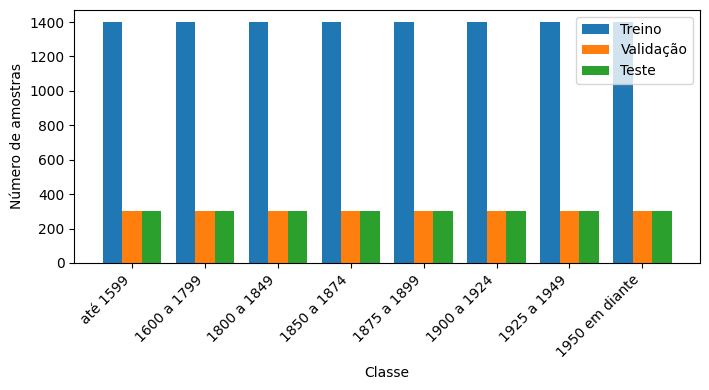

In [ ]:
PERIOD_NAMES = [name for name, _, _ in PERIODS]
SPLIT_NAMES = ["Treino", "Validação", "Teste"]

with stopwatch.measure("download"):
    parquet_paths = download_wikiart(DATA_DIR)
with stopwatch.measure("leitura dos metadados"):
    metadata = read_metadata(parquet_paths)

all_labels = [None if year is None else period_of(year) for year in metadata["year"]]
rows_total = len(all_labels)
rows_with_year = sum(label is not None for label in all_labels)
rows_per_period = {
    PERIOD_NAMES[label]: count
    for label, count in sorted(Counter(label for label in all_labels if label is not None).items())
}

selected = select_balanced(all_labels, PER_CLASS, SEED)
labels = [all_labels[index] for index in selected]
artists = [metadata["artist"][index] for index in selected]
styles = [metadata["style"][index] or "sem estilo" for index in selected]
titles = [metadata["title"][index] for index in selected]
years = [metadata["year"][index] for index in selected]

splits = split_by_group(artists, labels, seed=SEED)
train_indices, validation_indices, test_indices = splits

with stopwatch.measure("leitura das imagens"):
    encoded_images = read_images(parquet_paths, [metadata["row"][index] for index in selected])
with stopwatch.measure("redução das imagens para 64x64"):
    small_images = decode_images(encoded_images, IMAGE_SIZE)
label_tensor = torch.tensor(labels)

class_counts = {
    split_name: {
        name: sum(labels[index] == label for index in part) for label, name in enumerate(PERIOD_NAMES)
    }
    for split_name, part in zip(SPLIT_NAMES, splits)
}
split_sizes = {split_name: len(part) for split_name, part in zip(SPLIT_NAMES, splits)}
known_painters = [
    {artists[index] for index in part if not is_unknown_artist(artists[index])} for part in splits
]
painters_per_split = {split_name: len(names) for split_name, names in zip(SPLIT_NAMES, known_painters)}
unknown_painter_rows = {
    split_name: sum(is_unknown_artist(artists[index]) for index in part)
    for split_name, part in zip(SPLIT_NAMES, splits)
}
shared_painters = (
    (known_painters[0] & known_painters[1])
    | (known_painters[0] & known_painters[2])
    | (known_painters[1] & known_painters[2])
)

print("linhas no dataset:", rows_total)
print("linhas com ano:", rows_with_year)
print("linhas com ano por período, antes da amostra:", rows_per_period)
print("pinturas na amostra:", len(selected))
print("divisão:", split_sizes)
for split_name in SPLIT_NAMES:
    print(f"pinturas por período, {split_name}:", class_counts[split_name])
print("pintores conhecidos por parte:", painters_per_split)
print("pinturas sem pintor conhecido por parte:", unknown_painter_rows)
print("pintores presentes em mais de uma parte:", len(shared_painters))

class_counts_figure = plot_class_counts(class_counts, run.figures_dir / "class_counts.png")


## Verificações dos dados

- Nomes de pintores: quantos valores distintos existem na amostra, quais são os mais frequentes e se o mesmo pintor aparece escrito de formas diferentes. Grafias diferentes contariam como pintores diferentes na divisão. Nada é corrigido aqui, só relatado
- Pintor com mais pinturas em cada período e a parte em que ele ficou. Um pintor muito produtivo pode desequilibrar um período entre as partes
- Tamanho dos blocos (row groups) dos arquivos parquet, que define quanta memória a leitura das imagens usa
- Pico de memória RAM até aqui

In [ ]:
known_artist_counts = Counter(artist for artist in artists if not is_unknown_artist(artist))
variants_in_sample = spelling_variants(known_artist_counts)
variants_in_dataset = spelling_variants(
    {artist for artist in metadata["artist"] if not is_unknown_artist(artist)}
)
split_of_painter = {
    artist: split_name for split_name, names in zip(SPLIT_NAMES, known_painters) for artist in names
}
largest_painter_per_period = {}
for label, name in enumerate(PERIOD_NAMES):
    painter, count = Counter(
        artist
        for artist, painting_label in zip(artists, labels)
        if painting_label == label and not is_unknown_artist(artist)
    ).most_common(1)[0]
    largest_painter_per_period[name] = {
        "painter": painter,
        "paintings": count,
        "split": split_of_painter[painter],
    }
row_groups = [
    {"file": path.name, "groups": len(sizes), "smallest": min(sizes), "largest": max(sizes)}
    for path, sizes in zip(parquet_paths, row_group_sizes(parquet_paths))
]
painter_check = {
    "distinct_painters": len(known_artist_counts),
    "unknown_painter_rows": sum(unknown_painter_rows.values()),
    "most_frequent": dict(known_artist_counts.most_common(10)),
    "spelling_variants_in_sample": variants_in_sample,
    "spelling_variants_in_dataset": variants_in_dataset,
}
peak_ram_after_reading_mb = round(peak_ram_mb(), 1)

print("pintores distintos na amostra:", painter_check["distinct_painters"])
print("pinturas sem pintor conhecido na amostra:", painter_check["unknown_painter_rows"])
print("dez pintores mais frequentes na amostra:", painter_check["most_frequent"])
print("pintores com mais de uma grafia na amostra:", len(variants_in_sample), variants_in_sample[:10])
print("pintores com mais de uma grafia no dataset inteiro:", len(variants_in_dataset), variants_in_dataset[:10])
for name, entry in largest_painter_per_period.items():
    print(f"maior pintor em {name}: {entry['painter']}, {entry['paintings']} pinturas, {entry['split']}")
for entry in row_groups:
    print(
        f"{entry['file']}: {entry['groups']} blocos, de {entry['smallest']} a {entry['largest']} linhas"
    )
print("pico de memória RAM até aqui (MB):", peak_ram_after_reading_mb)


pintores distintos na amostra: 1553
pinturas sem pintor conhecido na amostra: 0
dez pintores mais frequentes na amostra: {'Camille Corot': 182, 'Ivan Aivazovsky': 132, 'Francisco Goya': 126, 'Rembrandt': 118, 'Edgar Degas': 107, 'Alfred Sisley': 105, 'Eugene Boudin': 102, 'Paul Cezanne': 99, 'Claude Monet': 97, 'Peter Paul Rubens': 93}
pintores com mais de uma grafia na amostra: 0 []
pintores com mais de uma grafia no dataset inteiro: 5 [['- Franz Kline', 'Franz Kline'], ['Driven by the Spirit', 'Driven by the spirit'], ['Original drawing', 'original drawing'], ['Trollet som grunner på hvor gammelt det er', 'Trollet som grunner på hvor gammelt det er,'], ['Waking Up', 'Waking up']]
maior pintor em até 1599: Titian, 82 pinturas, Treino
maior pintor em 1600 a 1799: Rembrandt, 118 pinturas, Treino
maior pintor em 1800 a 1849: Orest Kiprensky, 90 pinturas, Treino
maior pintor em 1850 a 1874: Camille Corot, 101 pinturas, Treino
maior pintor em 1875 a 1899: Paul Gauguin, 62 pinturas, Treino


## Modelo A: Vision Transformer treinado do zero

- Imagem de 64x64 cortada em patches de 8x8, o que dá 64 patches e um token de classe
- Embedding de 192 dimensões, 6 blocos, 3 cabeças de atenção por bloco
- Augmentation no treino: recorte aleatório com margem de 4 pixels e espelhamento horizontal
- Normalização com a média e o desvio padrão de cada canal, medidos no treino
- AdamW, taxa de aprendizado 0,001, weight decay 0,05, lotes de 256 imagens, 40 épocas
- A taxa de aprendizado sobe de forma linear nas 5 primeiras épocas e depois cai seguindo um cosseno

In [ ]:
channel_mean, channel_std = channel_statistics(small_images[train_indices])


def make_batches(indices, training):
    """Builds in-memory batches of the 64x64 images selected by the given indices."""
    return TensorBatches(
        small_images[indices],
        label_tensor[indices],
        SCRATCH_BATCH_SIZE,
        channel_mean,
        channel_std,
        augment=training,
        shuffle=training,
        seed=SEED,
        device=DEVICE,
    )


def summarize(model, history, report, train_seconds):
    """Gathers the parameters, history and test metrics of one model."""
    return {
        "parameters": sum(parameter.numel() for parameter in model.parameters()),
        "train_seconds": train_seconds,
        "history": history,
        "accuracy": report["accuracy"],
        "within_one_period": within_distance_accuracy(report["confusion"], distance=1),
        "macro_f1": macro_f1(report["confusion"]),
        "mean_distance": mean_class_distance(report["confusion"]),
        "per_class_accuracy": dict(zip(PERIOD_NAMES, report["per_class_accuracy"])),
        "confusion": report["confusion"],
    }


def train_scratch(name, use_positional_embedding):
    """Trains a Vision Transformer from scratch and evaluates it on the test split."""
    seed_everything(SEED)
    model = VisionTransformer(
        image_size=IMAGE_SIZE,
        num_classes=len(PERIOD_NAMES),
        use_positional_embedding=use_positional_embedding,
    ).to(DEVICE)
    train_batches = make_batches(train_indices, training=True)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=SCRATCH_LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = warmup_cosine_schedule(
        optimizer,
        warmup_steps=SCRATCH_WARMUP_EPOCHS * len(train_batches),
        total_steps=SCRATCH_EPOCHS * len(train_batches),
    )
    with stopwatch.measure(f"treino, {name}"):
        history = fit(
            model,
            train_batches,
            make_batches(validation_indices, training=False),
            optimizer,
            epochs=SCRATCH_EPOCHS,
            device=DEVICE,
            scheduler=scheduler,
        )
    with stopwatch.measure(f"avaliação, {name}"):
        report = evaluate(
            model, make_batches(test_indices, training=False), DEVICE, num_classes=len(PERIOD_NAMES)
        )
    return model, report, summarize(model, history, report, stopwatch.seconds[f"treino, {name}"])


SCRATCH_NAME = "ViT do zero"
scratch_model, scratch_report, scratch_summary = train_scratch(SCRATCH_NAME, use_positional_embedding=True)
print("parâmetros:", scratch_summary["parameters"])
print(f"acurácia no teste: {scratch_summary['accuracy']:.4f}")


epoch 1/40 train loss 2.0417 acc 0.2050 val loss 1.9366 acc 0.2342


epoch 2/40 train loss 1.9250 acc 0.2567 val loss 1.9347 acc 0.2396


epoch 3/40 train loss 1.8899 acc 0.2616 val loss 1.8891 acc 0.2383


epoch 4/40 train loss 1.8426 acc 0.2807 val loss 1.8429 acc 0.2600


epoch 5/40 train loss 1.8418 acc 0.2831 val loss 1.8704 acc 0.2571


...

epoch 37/40 train loss 1.4415 acc 0.4596 val loss 1.7748 acc 0.3221


epoch 38/40 train loss 1.4400 acc 0.4635 val loss 1.7813 acc 0.3158


epoch 39/40 train loss 1.4346 acc 0.4666 val loss 1.7809 acc 0.3142


epoch 40/40 train loss 1.4267 acc 0.4656 val loss 1.7814 acc 0.3142
treino, ViT do zero: 277.4 s


avaliação, ViT do zero: 0.6 s
parâmetros: 2720840
acurácia no teste: 0.3250


## Modelo A sem embedding posicional

- Mesmo modelo, mesma seed, mesmos dados e mesmo treino
- A única diferença: os tokens não recebem o embedding posicional
- Sem ele, o modelo vê os patches como um conjunto sem ordem. Trocar os patches de lugar não muda a saída

In [ ]:
NO_POSITION_NAME = "ViT do zero sem posição"
no_position_model, no_position_report, no_position_summary = train_scratch(
    NO_POSITION_NAME, use_positional_embedding=False
)
print("parâmetros:", no_position_summary["parameters"])
print(f"acurácia no teste: {no_position_summary['accuracy']:.4f}")


epoch 1/40 train loss 2.0226 acc 0.2093 val loss 1.9540 acc 0.2375


epoch 2/40 train loss 1.9215 acc 0.2513 val loss 1.9270 acc 0.2325


epoch 3/40 train loss 1.8868 acc 0.2673 val loss 1.8750 acc 0.2471


epoch 4/40 train loss 1.8490 acc 0.2825 val loss 1.8488 acc 0.2583


epoch 5/40 train loss 1.8495 acc 0.2817 val loss 1.8950 acc 0.2658


...

epoch 37/40 train loss 1.4789 acc 0.4449 val loss 1.8052 acc 0.3058


epoch 38/40 train loss 1.4670 acc 0.4487 val loss 1.8072 acc 0.3033


epoch 39/40 train loss 1.4620 acc 0.4522 val loss 1.8078 acc 0.3038


epoch 40/40 train loss 1.4639 acc 0.4521 val loss 1.8080 acc 0.3029
treino, ViT do zero sem posição: 280.1 s


avaliação, ViT do zero sem posição: 0.5 s
parâmetros: 2708360
acurácia no teste: 0.3246


## Modelo B: ViT-B/16 pré-treinado com fine-tuning

- ViT-B/16 do torchvision com pesos `IMAGENET1K_V1`
- A camada final é trocada por uma nova, com 8 saídas. Todas as camadas são treinadas
- Entrada igual à do pré-treinamento: redimensionar para 256, recorte central de 224x224 e normalização com média e desvio padrão da ImageNet
- AdamW, taxa de aprendizado 0,00003 no backbone e 0,001 na camada nova, weight decay 0,05
- Lotes de 32 imagens, precisão mista, 2 épocas

In [ ]:
pretrained_transform = imagenet_transform(PRETRAINED_RESIZE, PRETRAINED_CROP)


def make_loader(indices, shuffle):
    """Builds a loader that decodes the 256x256 images selected by the given indices."""
    dataset = EncodedImageDataset(
        [encoded_images[index] for index in indices],
        [labels[index] for index in indices],
        pretrained_transform,
    )
    return DataLoader(
        dataset,
        batch_size=PRETRAINED_BATCH_SIZE,
        shuffle=shuffle,
        num_workers=LOADER_WORKERS,
        pin_memory=DEVICE.type == "cuda",
    )


PRETRAINED_NAME = "ViT-B/16 pré-treinado"
seed_everything(SEED)
pretrained_model = build_pretrained_vit(num_classes=len(PERIOD_NAMES)).to(DEVICE)
pretrained_optimizer = torch.optim.AdamW(
    fine_tuning_groups(
        pretrained_model, PRETRAINED_BACKBONE_LEARNING_RATE, PRETRAINED_HEAD_LEARNING_RATE
    ),
    weight_decay=WEIGHT_DECAY,
)
with stopwatch.measure(f"treino, {PRETRAINED_NAME}"):
    pretrained_history = fit(
        pretrained_model,
        make_loader(train_indices, shuffle=True),
        make_loader(validation_indices, shuffle=False),
        pretrained_optimizer,
        epochs=PRETRAINED_EPOCHS,
        device=DEVICE,
        use_amp=True,
    )
with stopwatch.measure(f"avaliação, {PRETRAINED_NAME}"):
    pretrained_report = evaluate(
        pretrained_model,
        make_loader(test_indices, shuffle=False),
        DEVICE,
        num_classes=len(PERIOD_NAMES),
        use_amp=True,
    )
pretrained_summary = summarize(
    pretrained_model,
    pretrained_history,
    pretrained_report,
    stopwatch.seconds[f"treino, {PRETRAINED_NAME}"],
)
print("parâmetros:", pretrained_summary["parameters"])
print(f"acurácia no teste: {pretrained_summary['accuracy']:.4f}")


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


  0%|          | 0.00/330M [00:00<?, ?B/s]

  4%|▍         | 13.6M/330M [00:00<00:02, 142MB/s]

 10%|▉         | 32.0M/330M [00:00<00:01, 171MB/s]

 15%|█▌        | 50.4M/330M [00:00<00:01, 181MB/s]

...

 97%|█████████▋| 319M/330M [00:05<00:00, 52.4MB/s]

100%|██████████| 330M/330M [00:05<00:00, 59.3MB/s]

epoch 1/2 train loss 1.4081 acc 0.4573 val loss 1.3322 acc 0.4888


epoch 2/2 train loss 0.8655 acc 0.6771 val loss 1.4307 acc 0.4904
treino, ViT-B/16 pré-treinado: 236.0 s


avaliação, ViT-B/16 pré-treinado: 7.7 s
parâmetros: 85804808
acurácia no teste: 0.4737


## Avaliação no conjunto de teste

- Acurácia: fração de pinturas com o período exato
- Acurácia com tolerância de um período: conta como acerto errar por um período vizinho
- F1 macro: média do F1 dos oito períodos
- Distância média: quantos períodos, em média, separam a previsão do período real
- Com oito classes balanceadas, um chute ao acaso acerta cerca de 12,5%
- Matriz de confusão do Modelo A e do Modelo B, e curvas de perda e acurácia dos três treinos

ViT do zero: acurácia 0.3250, com tolerância de um período 0.6400, F1 macro 0.3202, distância média 1.4925, parâmetros 2720840, treino 277.4 s
ViT do zero sem posição: acurácia 0.3246, com tolerância de um período 0.6446, F1 macro 0.3217, distância média 1.4746, parâmetros 2708360, treino 280.1 s
ViT-B/16 pré-treinado: acurácia 0.4737, com tolerância de um período 0.8021, F1 macro 0.4578, distância média 0.9308, parâmetros 85804808, treino 236.0 s
acurácia por período, ViT do zero:
  até 1599: 0.5100
  1600 a 1799: 0.4567
  1800 a 1849: 0.2567
  1850 a 1874: 0.2467
  1875 a 1899: 0.2800
  1900 a 1924: 0.1733
  1925 a 1949: 0.1600
  1950 em diante: 0.5167
acurácia por período, ViT do zero sem posição:
  até 1599: 0.5133
  1600 a 1799: 0.4500
  1800 a 1849: 0.2433
  1850 a 1874: 0.2400
  1875 a 1899: 0.2300
  1900 a 1924: 0.1767
  1925 a 1949: 0.2167
  1950 em diante: 0.5267
acurácia por período, ViT-B/16 pré-treinado:
  até 1599: 0.8967
  1600 a 1799: 0.4767
  1800 a 1849: 0.3867
  1850

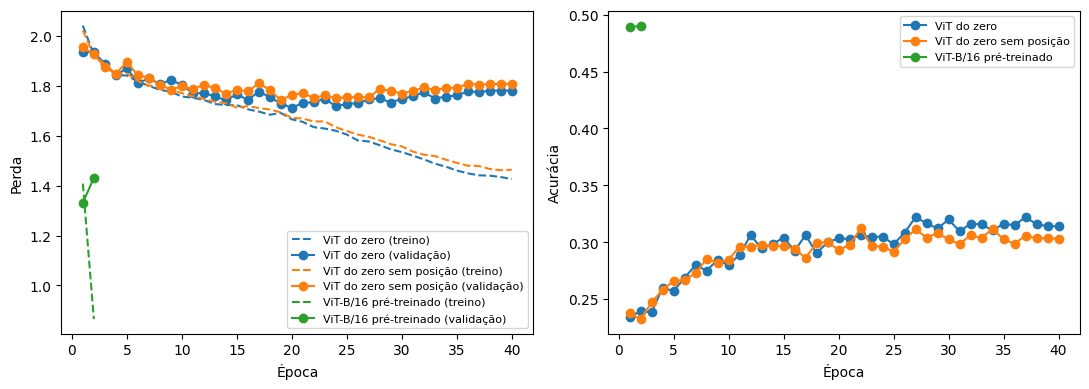

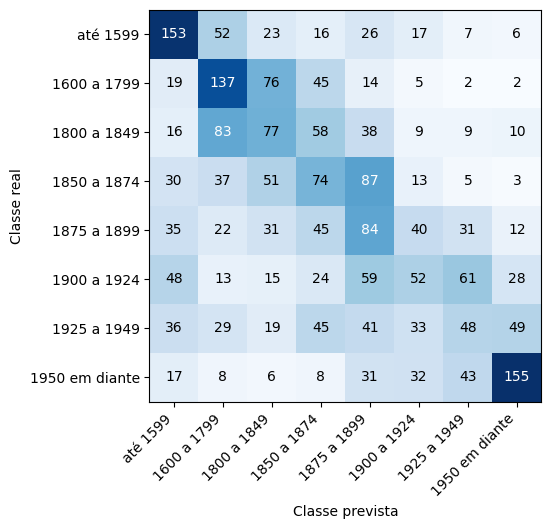

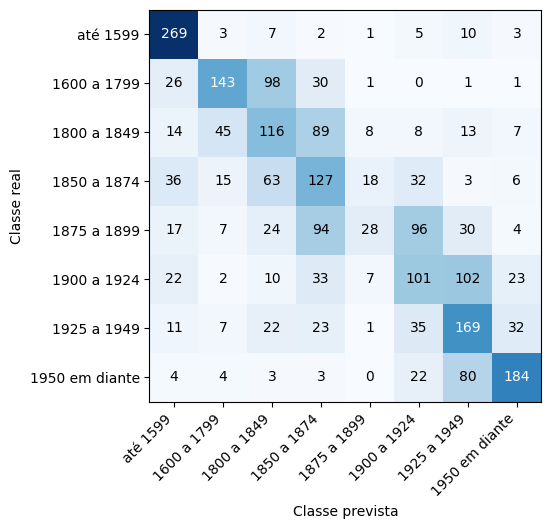

In [ ]:
summaries = {
    SCRATCH_NAME: scratch_summary,
    NO_POSITION_NAME: no_position_summary,
    PRETRAINED_NAME: pretrained_summary,
}
for name, summary in summaries.items():
    print(
        f"{name}: acurácia {summary['accuracy']:.4f}, "
        f"com tolerância de um período {summary['within_one_period']:.4f}, "
        f"F1 macro {summary['macro_f1']:.4f}, "
        f"distância média {summary['mean_distance']:.4f}, "
        f"parâmetros {summary['parameters']}, "
        f"treino {summary['train_seconds']} s"
    )
for name, summary in summaries.items():
    print(f"acurácia por período, {name}:")
    for period, value in summary["per_class_accuracy"].items():
        print(f"  {period}: {value:.4f}")

histories_figure = plot_histories(
    {name: summary["history"] for name, summary in summaries.items()},
    run.figures_dir / "histories.png",
)
scratch_confusion_figure = plot_confusion(
    scratch_summary["confusion"], PERIOD_NAMES, run.figures_dir / "confusion_scratch.png"
)
pretrained_confusion_figure = plot_confusion(
    pretrained_summary["confusion"], PERIOD_NAMES, run.figures_dir / "confusion_pretrained.png"
)


## Mapas de atenção do Modelo A

- Seis pinturas do teste: três que o Modelo A acertou e três que errou, de períodos diferentes. A escolha é fixa: a primeira pintura de cada período escolhido
- Primeira figura: atenção do token de classe para cada patch, em cada uma das 3 cabeças do último bloco
- Segunda figura: a mesma atenção no primeiro bloco, na média das 3 cabeças
- Cada painel usa sua própria escala de cores, do menor ao maior valor daquele painel. As cores mostram onde a atenção é maior dentro de um painel. Elas não servem para comparar um painel com outro

pintura 1: The Nymph of the Spring, Lucas Cranach the Elder, 1540, real até 1599, previsto até 1599
pintura 2: Torso of a Dancer, Edgar Degas, 1899, real 1875 a 1899, previsto 1875 a 1899
pintura 3: Pastorale, Ernst Wilhelm Nay, 1954, real 1950 em diante, previsto 1950 em diante
pintura 4: Jane Maxwell (c.1749–1812), Duchess of Gordon, Wife of the 4th Duke of Gordon, with her Son, George Duncan (1770–1836), Marquess of Huntly, Later 5th Duke of Gordon, George Romney, 1778, real 1600 a 1799, previsto 1800 a 1849
pintura 5: Madame Gobillard, Yves Morisot, Edgar Degas, 1869, real 1850 a 1874, previsto 1900 a 1924
pintura 6: Milking the Cow , Yasuo Kuniyoshi, 1927, real 1925 a 1949, previsto 1950 em diante


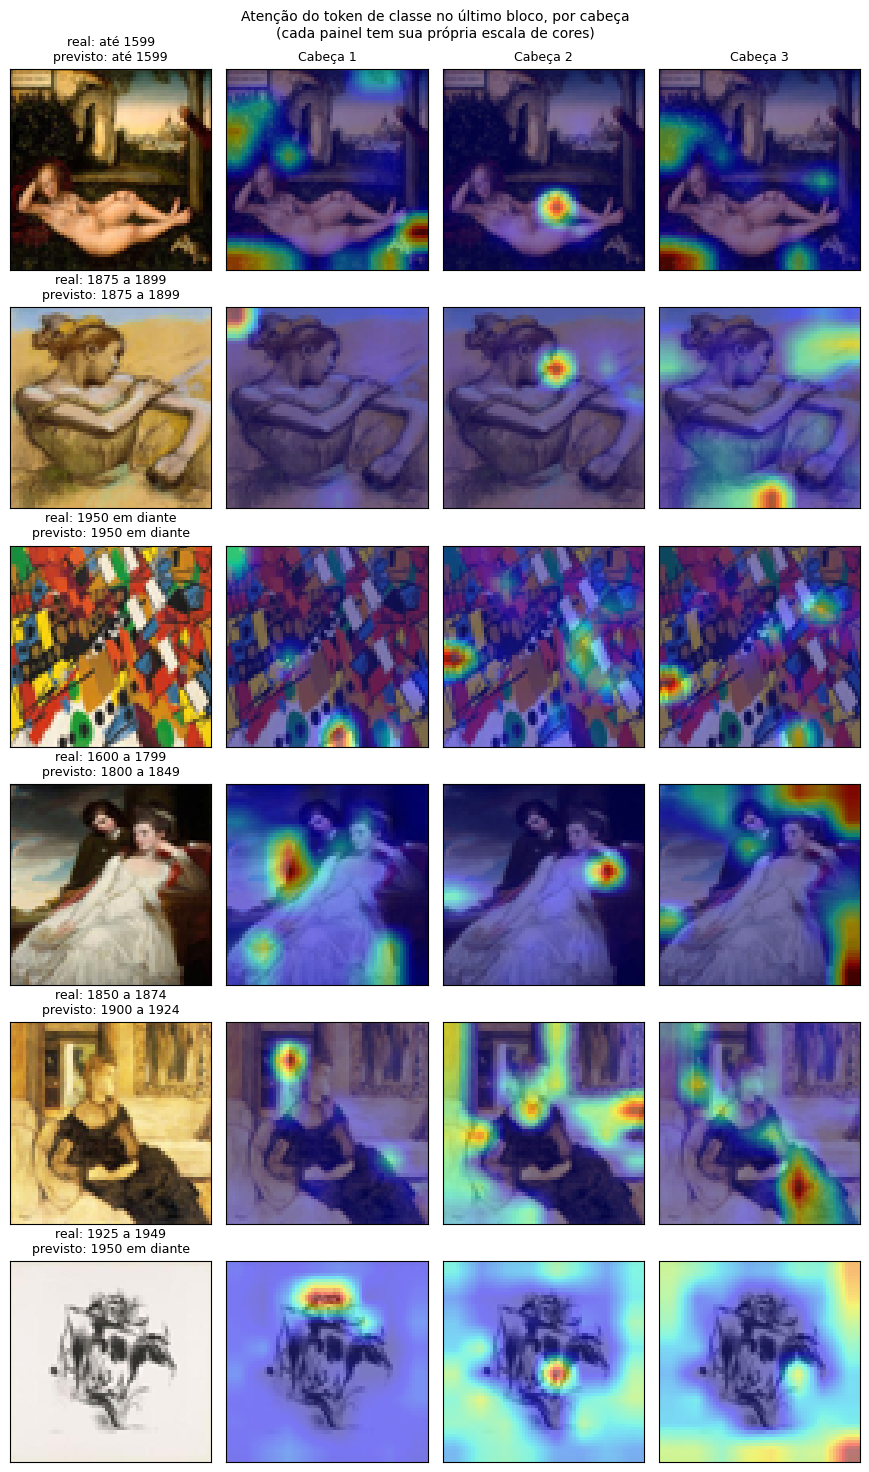

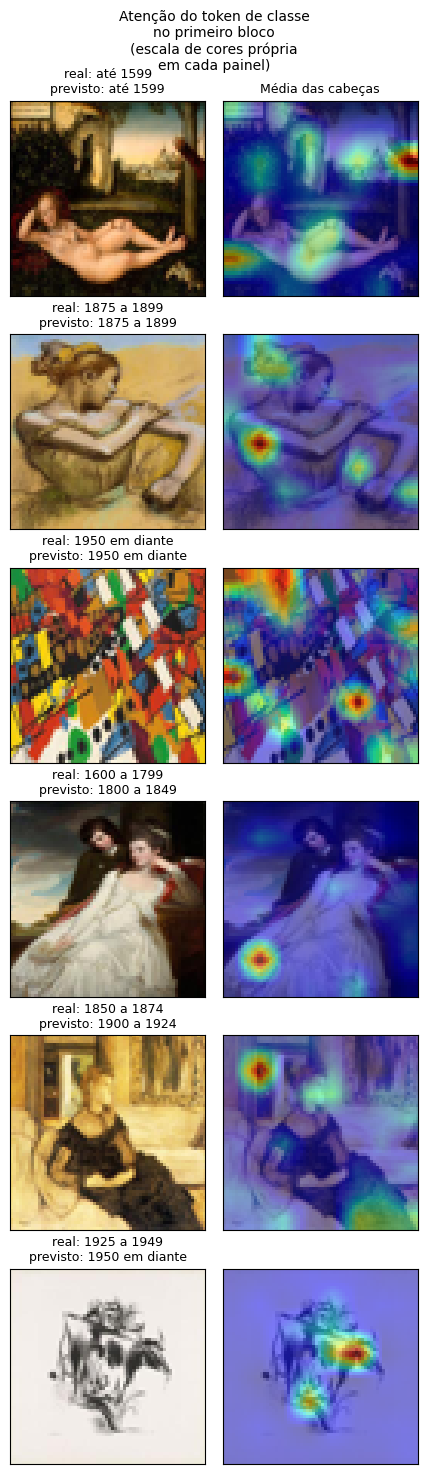

In [ ]:
example_positions = select_examples(
    scratch_report["targets"], scratch_report["predictions"], per_outcome=EXAMPLES_PER_OUTCOME
)
example_indices = [test_indices[position] for position in example_positions]
example_batches = TensorBatches(
    small_images[example_indices],
    label_tensor[example_indices],
    len(example_indices),
    channel_mean,
    channel_std,
    device=DEVICE,
)
example_inputs, _ = next(iter(example_batches))
scratch_model.eval()
with torch.no_grad():
    _, example_attention = scratch_model(example_inputs, return_attention=True)
grid_size = scratch_model.patch_embedding.grid_size
last_block_maps = class_token_attention(example_attention[-1], grid_size).cpu()
first_block_maps = class_token_attention(example_attention[0], grid_size).mean(dim=1, keepdim=True).cpu()

attention_examples = [
    {
        "title": titles[index],
        "painter": artists[index],
        "year": years[index],
        "true_period": PERIOD_NAMES[labels[index]],
        "predicted_period": PERIOD_NAMES[scratch_report["predictions"][position]],
    }
    for position, index in zip(example_positions, example_indices)
]
for number, example in enumerate(attention_examples, start=1):
    print(
        f"pintura {number}: {example['title']}, {example['painter']}, {example['year']}, "
        f"real {example['true_period']}, previsto {example['predicted_period']}"
    )
example_titles = [
    f"real: {example['true_period']}\nprevisto: {example['predicted_period']}"
    for example in attention_examples
]
last_block_figure = plot_attention_maps(
    small_images[example_indices],
    last_block_maps,
    example_titles,
    run.figures_dir / "attention_last_block.png",
    title="Atenção do token de classe no último bloco, por cabeça\n(cada painel tem sua própria escala de cores)",
)
first_block_figure = plot_attention_maps(
    small_images[example_indices],
    first_block_maps,
    example_titles,
    run.figures_dir / "attention_first_block.png",
    panel_titles=["Média das cabeças"],
    title="Atenção do token de classe\nno primeiro bloco\n(escala de cores própria\nem cada painel)",
)


## Acurácia por movimento artístico

- As previsões no teste são agrupadas pelo movimento da pintura (coluna `style`)
- Só entram movimentos com pelo menos 20 pinturas no teste
- Um gráfico para o Modelo A e outro para o Modelo B

acurácia por movimento, ViT do zero:
  Romanticism: 0.2563 (n=437, distância média 1.27)
  Realism: 0.2828 (n=244, distância média 1.29)
  Northern Renaissance: 0.5094 (n=212, distância média 1.28)
  Impressionism: 0.2750 (n=200, distância média 1.55)
  Rococo: 0.4342 (n=152, distância média 0.86)
  Expressionism: 0.1484 (n=128, distância média 2.47)
  Surrealism: 0.1901 (n=121, distância média 2.12)
  Symbolism: 0.1633 (n=98, distância média 1.87)
  Post-Impressionism: 0.2667 (n=75, distância média 1.40)
  Naïve Art (Primitivism): 0.2923 (n=65, distância média 1.80)
  Abstract Expressionism: 0.6393 (n=61, distância média 1.15)
  Early Renaissance: 0.5000 (n=54, distância média 1.76)
  Baroque: 0.4800 (n=50, distância média 1.00)
  Cubism: 0.3636 (n=33, distância média 1.67)
  Neoclassicism: 0.0968 (n=31, distância média 2.52)
  Tenebrism: 0.6552 (n=29, distância média 0.48)
  Art Nouveau (Modern): 0.2083 (n=24, distância média 2.67)
  Academicism: 0.1304 (n=23, distância média 1.70)
 

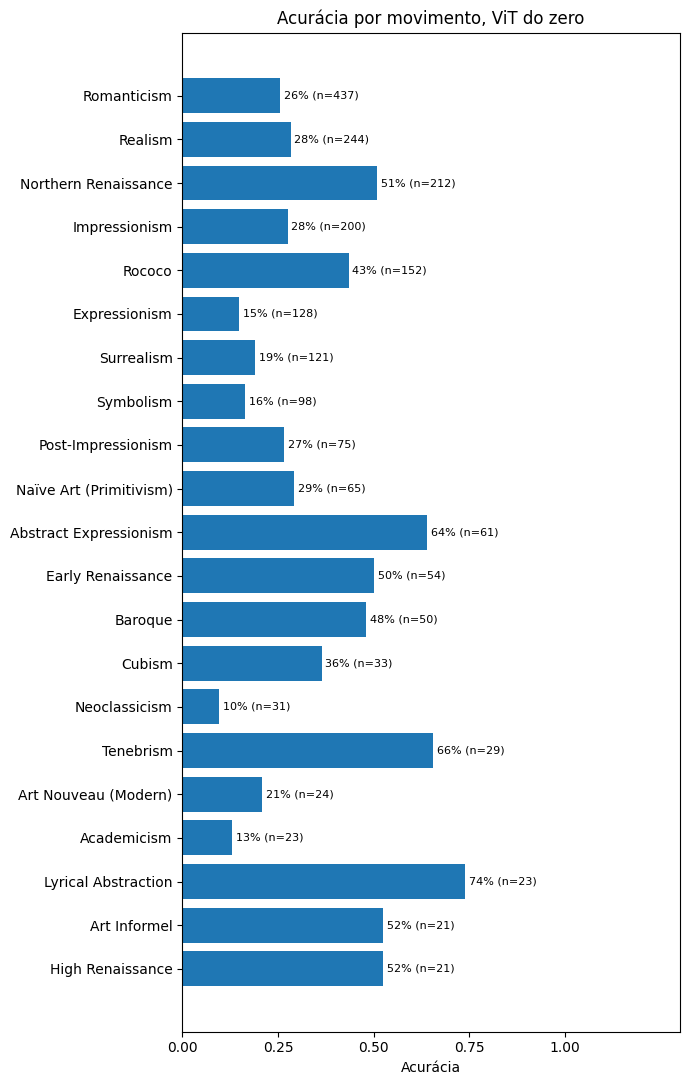

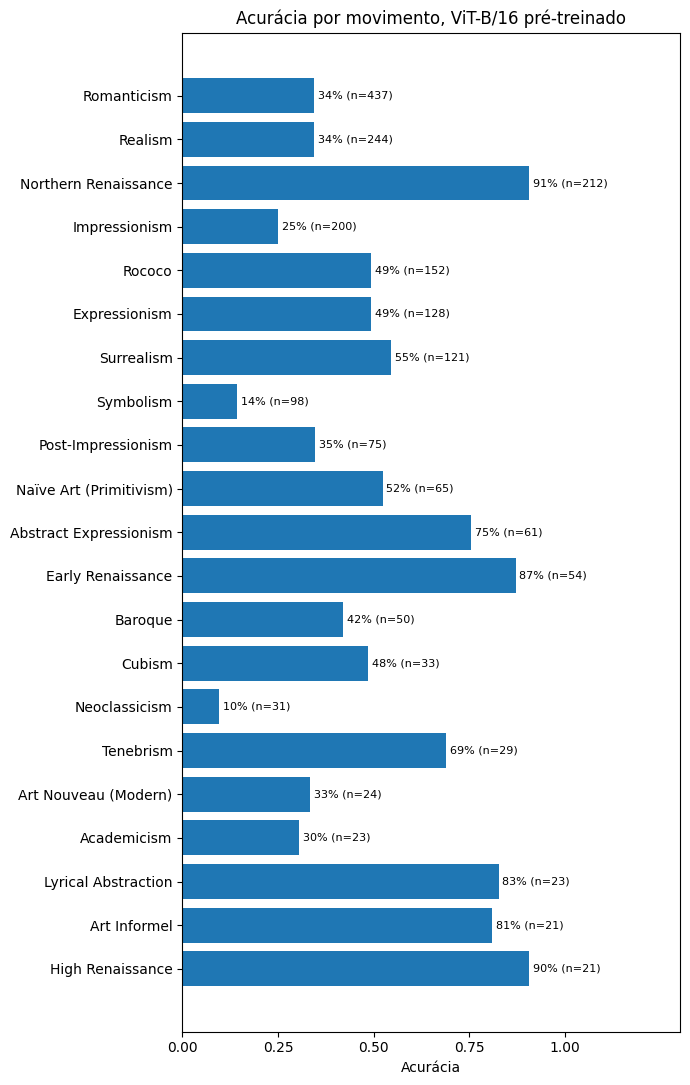

In [ ]:
test_styles = [styles[index] for index in test_indices]
by_style = {
    name: accuracy_by_group(
        report["targets"], report["predictions"], test_styles, minimum=MINIMUM_PER_STYLE
    )
    for name, report in [(SCRATCH_NAME, scratch_report), (PRETRAINED_NAME, pretrained_report)]
}
for name, entries in by_style.items():
    print(f"acurácia por movimento, {name}:")
    for entry in entries:
        print(
            f"  {entry['group']}: {entry['accuracy']:.4f} "
            f"(n={entry['count']}, distância média {entry['mean_distance']:.2f})"
        )

scratch_styles_figure = plot_group_accuracy(
    by_style[SCRATCH_NAME],
    run.figures_dir / "styles_scratch.png",
    f"Acurácia por movimento, {SCRATCH_NAME}",
)
pretrained_styles_figure = plot_group_accuracy(
    by_style[PRETRAINED_NAME],
    run.figures_dir / "styles_pretrained.png",
    f"Acurácia por movimento, {PRETRAINED_NAME}",
)


## Leitura dos resultados

- A preencher depois da primeira execução na T4.

In [ ]:
metrics = {
    "periods": PERIOD_NAMES,
    "class_counts": class_counts,
    "split_sizes": split_sizes,
    "painters_per_split": painters_per_split,
    "unknown_painter_rows": unknown_painter_rows,
    "shared_painters": len(shared_painters),
    "rows_total": rows_total,
    "rows_with_year": rows_with_year,
    "rows_per_period": rows_per_period,
    "painter_check": painter_check,
    "largest_painter_per_period": largest_painter_per_period,
    "row_groups": row_groups,
    "peak_ram_after_reading_mb": peak_ram_after_reading_mb,
    "hyperparameters": {
        "seed": SEED,
        "per_class": PER_CLASS,
        "scratch": {
            "image_size": IMAGE_SIZE,
            "patch_size": 8,
            "embed_dim": 192,
            "depth": 6,
            "num_heads": 3,
            "batch_size": SCRATCH_BATCH_SIZE,
            "epochs": SCRATCH_EPOCHS,
            "warmup_epochs": SCRATCH_WARMUP_EPOCHS,
            "learning_rate": SCRATCH_LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "optimizer": "AdamW",
            "schedule": "linear warm-up, cosine decay",
            "augmentation": "random crop with padding 4, horizontal flip",
            "channel_mean": channel_mean,
            "channel_std": channel_std,
        },
        "pretrained": {
            "backbone": "vit_b_16 IMAGENET1K_V1",
            "resize": PRETRAINED_RESIZE,
            "crop": PRETRAINED_CROP,
            "batch_size": PRETRAINED_BATCH_SIZE,
            "epochs": PRETRAINED_EPOCHS,
            "backbone_learning_rate": PRETRAINED_BACKBONE_LEARNING_RATE,
            "head_learning_rate": PRETRAINED_HEAD_LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "optimizer": "AdamW",
            "mixed_precision": True,
        },
    },
    "models": summaries,
    "by_style": by_style,
    "attention_examples": attention_examples,
    "step_seconds": stopwatch.seconds,
}
archive = save_run(run, metrics)
saved = json.loads((run.output_dir / "metrics.json").read_text(encoding="utf-8"))
print("arquivo de saída:", archive)
print("tempo total (s):", saved["runtime_seconds"])
print("pico de memória de GPU (MB):", saved["peak_gpu_memory_mb"])
print("pico de memória RAM (MB):", saved["peak_ram_mb"])


arquivo de saída: outputs_a1.zip
tempo total (s): 866.6
pico de memória de GPU (MB): 3971.6
pico de memória RAM (MB): 2867.3
